# **AE Complex 2 VGG: pérdida perceptual con latente de 256 dimensiones**

## **0. Introducción y objetivo**

En `AE_complex2` comprobamos que añadir bloques residuales no mejoraba el FID (`64.40` frente a `63.65` de `AE_complex1_latent`), y concluimos que el problema no estaba en la profundidad de la red sino en lo que le pedimos que optimice. Por eso, en este notebook cambiamos el **objetivo** y no la arquitectura.

Se trata de una variante controlada de `AE_complex1_latent`: usamos las mismas imágenes RGB de `64x64`, la misma arquitectura convolucional (sin bloques residuales, que no nos aportaron nada), el mismo latente de `256` dimensiones, la misma semilla, el mismo Cosine Decay y `30` épocas. La única modificación es la función de pérdida: además de `L1 + (1 - SSIM)`, añadimos una pérdida basada en las activaciones tempranas de una VGG16 congelada.

Al final analizamos el resultado y el coste de la pérdida VGG, repasamos las técnicas que probamos durante esta búsqueda y no mantuvimos, y proponemos mejoras futuras.

---

## **1. Configuración e imports**

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

import torch
from torchmetrics.image.fid import FrechetInceptionDistance

from PIL import Image
from IPython.display import Image as IPyImage, display

In [2]:
SEED = 1234
IMG_SIZE = 64
CHANNELS = 3
# Experimento de pérdida perceptual: misma arquitectura, resolución y latente que AE_complex1_latent.
LATENT_DIM = 256
BATCH_SIZE = 128
EPOCHS = 30

TRAIN_MODEL = False
NOTEBOOK_NAME = "ae_complex2_vgg256"

PROCESSED_DIR = Path("../data/processed")

# Verificar que están los 9 archivos requeridos
_required_data_files = tuple(
    Path(split) / filename
    for split in ("train", "val", "test")
    for filename in ("x.npy", "attrs.npy", "ids.npy")
)
if not all((PROCESSED_DIR / relative_path).is_file() for relative_path in _required_data_files):
    raise FileNotFoundError(f"Faltan algunos archivos en {PROCESSED_DIR.resolve()}")

CHECKPOINT_DIR = Path("checkpoints")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

AE_PATH = CHECKPOINT_DIR / f"{NOTEBOOK_NAME}.keras"
ENCODER_PATH = CHECKPOINT_DIR / f"encoder_{NOTEBOOK_NAME.replace('ae_', '')}.keras"
DECODER_PATH = CHECKPOINT_DIR / f"decoder_{NOTEBOOK_NAME.replace('ae_', '')}.keras"
HISTORY_PATH = CHECKPOINT_DIR / f"{NOTEBOOK_NAME}_history.json"

np.random.seed(SEED)
tf.random.set_seed(SEED)
print(f"Datos localizados correctamente en: {PROCESSED_DIR.resolve()}")

Datos localizados correctamente en: /Users/dani22/Desktop/ProyectoCD/morphing/data/processed


In [3]:
import tensorflow as tf

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"GPU detectada: {gpus}")
else:
    print("Corriendo en CPU.")

GPU detectada: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


---

## **2. Carga de `train`, `val` y `test`**

In [4]:
def load_split(name):
    split_dir = PROCESSED_DIR / name
    x = np.load(split_dir / "x.npy", allow_pickle=False)
    attrs = np.load(split_dir / "attrs.npy", allow_pickle=False)
    ids = np.load(split_dir / "ids.npy", allow_pickle=True)
    if x.ndim != 4 or x.shape[1:] != (IMG_SIZE, IMG_SIZE, CHANNELS):
        raise ValueError(f"{name}/x.npy tiene forma {x.shape}; se esperaba (N, 64, 64, 3)")
    if attrs.shape[0] != x.shape[0] or ids.shape[0] != x.shape[0]:
        raise ValueError(f"Los archivos de {name} no tienen el mismo número de ejemplos")
    return x.astype("float32") / 255.0, attrs, ids

x_train, attrs_train, ids_train = load_split("train")
x_val, attrs_val, ids_val = load_split("val")
x_test, attrs_test, ids_test = load_split("test")

print(f"train: {x_train.shape}, val: {x_val.shape}, test: {x_test.shape}")
print(f"Rango train: [{x_train.min():.3f}, {x_train.max():.3f}]")


train: (60000, 64, 64, 3), val: (5000, 64, 64, 3), test: (10000, 64, 64, 3)
Rango train: [0.000, 1.000]


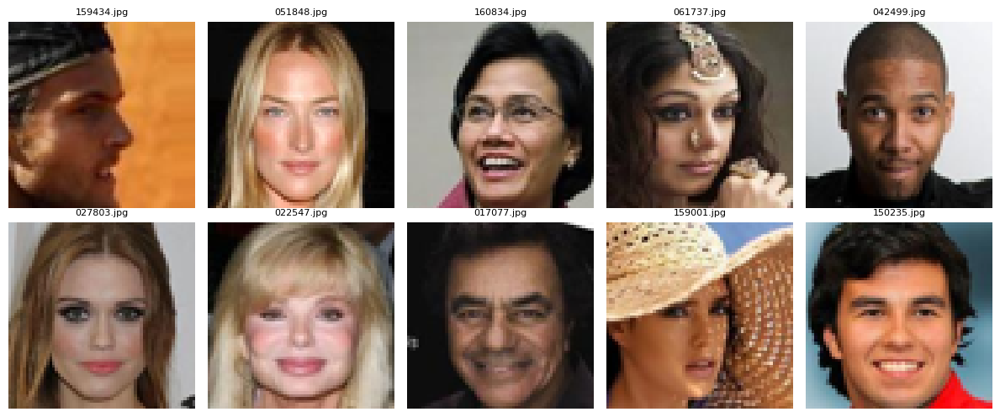

In [5]:
def show_images(images, titles=None, cols=5, figsize=(12, 8)):
    rows = int(np.ceil(len(images) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=figsize, squeeze=False)
    for ax, image, index in zip(axes.flat, images, range(len(images))):
        ax.imshow(np.clip(image, 0, 1))
        ax.axis("off")
        if titles is not None:
            ax.set_title(str(titles[index]), fontsize=8)
    for ax in axes.flat[len(images):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

sample_rng = np.random.default_rng(SEED)
sample_indices = sample_rng.choice(len(x_train), size=10, replace=False)
show_images(x_train[sample_indices], ids_train[sample_indices], cols=5, figsize=(12, 5))


---

## **3. Encoder, decoder y autoencoder**

No incorporamos los bloques residuales de `AE_complex2`. Aportaban más de parámetros y cómputo sin mejorar el FID, por lo que partimos de la arquitectura de `AE_complex1_latent` y cambiamos únicamente la función de pérdida.

In [6]:
encoder_inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, CHANNELS), name="encoder_input")
x = encoder_inputs
for filters in (32, 64, 128, 256):
    x = layers.Conv2D(filters, kernel_size=4, strides=2, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(negative_slope=0.2)(x)
x = layers.Flatten()(x)
z = layers.Dense(
    LATENT_DIM,
    kernel_regularizer=keras.regularizers.l2(1e-5),
    name="latent_vector",
)(x)
encoder_ae = keras.Model(encoder_inputs, z, name="encoder_ae")
encoder_ae.summary()


2026-11-02 10:55:39.458419: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M5
2026-11-02 10:55:39.458446: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 24.00 GB
2026-11-02 10:55:39.458455: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 8.88 GB
2026-11-02 10:55:39.458473: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-11-02 10:55:39.458488: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Model: "encoder_ae"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_input (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │         1,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        32,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │       131,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 4, 4, 256)      │       524,288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 4, 4, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_vector (Dense)           │ (None, 256)            │     1,048,832 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,740,416 (6.64 MB)

 Trainable params: 1,739,456 (6.64 MB)

 Non-trainable params: 960 (3.75 KB)

In [7]:
decoder_inputs = keras.Input(shape=(LATENT_DIM,), name="decoder_input")
x = layers.Dense(4 * 4 * 256, use_bias=False)(decoder_inputs)
x = layers.BatchNormalization()(x)
x = layers.LeakyReLU(negative_slope=0.2)(x)
x = layers.Reshape((4, 4, 256))(x)

for filters in (256, 128, 64, 32):
    x = layers.UpSampling2D(size=(2, 2), interpolation="bilinear")(x)
    x = layers.Conv2D(filters, kernel_size=3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(negative_slope=0.2)(x)

decoder_outputs = layers.Conv2D(
    CHANNELS, kernel_size=3, padding="same", activation="sigmoid", name="decoder_output"
)(x)
decoder_ae = keras.Model(decoder_inputs, decoder_outputs, name="decoder_ae")
decoder_ae.summary()


Model: "decoder_ae"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ decoder_input (InputLayer)      │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4096)           │     1,048,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 4096)           │        16,384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 256)      │       589,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_5 (LeakyReLU)       │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 128)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_6 (LeakyReLU)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_2 (UpSampling2D)  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 32, 32, 64)     │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_7 (LeakyReLU)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_3 (UpSampling2D)  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 64, 64, 32)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_8 (LeakyReLU)       │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_output (Conv2D)         │ (None, 64, 64, 3)      │           867 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 2,044,643 (7.80 MB)

 Trainable params: 2,035,491 (7.76 MB)

 Non-trainable params: 9,152 (35.75 KB)

In [8]:
autoencoder_input = keras.Input(shape=(IMG_SIZE, IMG_SIZE, CHANNELS), name="autoencoder_input")
autoencoder = keras.Model(
    autoencoder_input,
    decoder_ae(encoder_ae(autoencoder_input)),
    name="autoencoder",
)
autoencoder.summary()

Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ autoencoder_input (InputLayer)  │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_ae (Functional)         │ (None, 256)            │     1,740,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_ae (Functional)         │ (None, 64, 64, 3)      │     2,044,643 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,785,059 (14.44 MB)

 Trainable params: 3,774,947 (14.40 MB)

 Non-trainable params: 10,112 (39.50 KB)

---

## **4. Función de pérdida perceptual**

### **Qué problema queremos resolver**

$L_1$ y SSIM comparan píxeles y ventanas locales de la imagen. Una reconstrucción puede tener un error de píxel bajo y aun así parecer borrosa, porque estas métricas penalizan poco la pérdida de texturas finas (poros, pestañas, mechones de pelo) y el FID, que mide realismo en el espacio de una red Inception, sí lo nota. Nos interesa una pérdida que compare las imágenes como lo hace una red de visión.

### **Cómo funciona**

Una **pérdida perceptual** no compara las imágenes directamente, sino sus **activaciones** en una red preentrenada. Pasamos la imagen original y la reconstruida por VGG16 (entrenada en ImageNet) y medimos la diferencia entre sus mapas de características en algunas capas:

$$L_{total} = \underbrace{0.5\,L_1 + 0.5\,(1 - SSIM)}_{\text{pérdida base}} + \lambda\, L_{VGG}, \qquad L_{VGG} = \sum_{l \in \{\text{block1\_conv2},\,\text{block2\_conv2}\}} \left\| \phi_l(x) - \phi_l(\hat{x}) \right\|_1$$

donde $\phi_l$ son las activaciones de la capa $l$. Si dos imágenes producen activaciones parecidas, activan los mismos detectores de bordes y texturas y, por tanto, se ven parecidas, aunque no coincidan píxel a píxel.

### **Decisiones de diseño**

- **VGG16 congelada (`trainable = False`):** solo la usamos como extractor de características; no se actualiza ni añade parámetros entrenables al autoencoder.
- **Capas tempranas (`block1_conv2` y `block2_conv2`):** capturan bordes, texturas y estructuras locales. Las capas profundas codifican semántica abstracta (objetos, clases de ImageNet), que no nos interesa en caras de `64x64` y que podría imponer una estructura ajena al problema.
- **Se suma a la pérdida base, no la sustituye:** la pérdida de píxel mantiene el color y la luminancia correctos, algo que las activaciones tempranas de VGG no garantizan por sí solas.
- **Peso pequeño (`LAMBDA = 1e-4`):** las entradas se convierten con `preprocess_input` a la escala `0–255` de VGG, de modo que las activaciones tienen magnitudes grandes. Con un peso pequeño la pérdida VGG ayuda a conservar detalle sin dominar la optimización. No hemos barrido este hiperparámetro.

### **Limitaciones**

VGG16 se entrenó con imágenes de `224x224` de ImageNet, no con caras de `64x64`, y su noción de similitud no coincide exactamente con la del FID. Por ello no esperamos milagros. Además, esta pérdida **no es comparable en valor** con las anteriores: la `loss` y la `val_loss` de este notebook incluyen un término adicional, por lo que no podemos comparar `0.1262` con los `0.1077` de `AE_complex1_latent`. Para comparar usamos el FID.

In [9]:
def ssim_l1_loss(y_true, y_pred):
    l1 = tf.reduce_mean(tf.abs(y_true - y_pred))
    structural_loss = 1.0 - tf.reduce_mean(tf.image.ssim(y_true, y_pred, max_val=1.0))
    return 0.5 * l1 + 0.5 * structural_loss

LAMBDA = 1e-4
vgg = keras.applications.VGG16(
    include_top=False,
    weights="imagenet",
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
)
vgg.trainable = False
LAYERS = ["block1_conv2", "block2_conv2"]
feat = keras.Model(vgg.input, [vgg.get_layer(name).output for name in LAYERS], name="vgg_features")
feat.trainable = False


def perceptual(y_true, y_pred):
    preprocess = lambda x: keras.applications.vgg16.preprocess_input(x * 255.0)
    true_features = feat(preprocess(y_true), training=False)
    pred_features = feat(preprocess(y_pred), training=False)
    return tf.add_n([
        tf.reduce_mean(tf.abs(true - pred))
        for true, pred in zip(true_features, pred_features)
    ])


def full_loss(y_true, y_pred):
    return ssim_l1_loss(y_true, y_pred) + LAMBDA * perceptual(y_true, y_pred)


INITIAL_LEARNING_RATE = 1e-3
MIN_LEARNING_RATE = 1e-5
DECAY_STEPS = int(np.ceil(len(x_train) / BATCH_SIZE) * EPOCHS)
learning_rate_schedule = keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=INITIAL_LEARNING_RATE,
    decay_steps=DECAY_STEPS,
    alpha=MIN_LEARNING_RATE / INITIAL_LEARNING_RATE,
)

autoencoder.compile(
    optimizer=keras.optimizers.Adam(learning_rate=learning_rate_schedule),
    loss=full_loss,
)
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
]


---

## **5. Entrenamiento y guardado**

In [10]:
if TRAIN_MODEL:
    history_ae = autoencoder.fit(
        x_train,
        x_train,
        batch_size=BATCH_SIZE,
        epochs=EPOCHS,
        validation_data=(x_val, x_val),
        callbacks=callbacks,
    )
    CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
    autoencoder.save(AE_PATH)
    encoder_ae.save(ENCODER_PATH)
    decoder_ae.save(DECODER_PATH)
    HISTORY_PATH.write_text(json.dumps({
        key: [float(value) for value in values]
        for key, values in history_ae.history.items()
    }, indent=2))
else:
    required = [AE_PATH, ENCODER_PATH, DECODER_PATH, HISTORY_PATH]
    missing = [str(path) for path in required if not path.exists()]
    if missing:
        raise FileNotFoundError("Faltan checkpoints para TRAIN_MODEL=False: " + ", ".join(missing))
    autoencoder = keras.models.load_model(AE_PATH, custom_objects={"ssim_l1_loss": ssim_l1_loss, "perceptual": perceptual, "full_loss": full_loss})
    encoder_ae = keras.models.load_model(ENCODER_PATH)
    decoder_ae = keras.models.load_model(DECODER_PATH)
    history_ae = type("History", (), {"history": json.loads(HISTORY_PATH.read_text())})()


Epoch 1/30


2026-11-02 10:55:51.647563: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


469/469 ━━━━━━━━━━━━━━━━━━━━ 210s 439ms/step - loss: 0.3457 - val_loss: 0.2645
Epoch 2/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 212s 452ms/step - loss: 0.2265 - val_loss: 0.2130
Epoch 3/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 218s 465ms/step - loss: 0.1978 - val_loss: 0.2026
Epoch 4/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 218s 464ms/step - loss: 0.1816 - val_loss: 0.1894
Epoch 5/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 224s 477ms/step - loss: 0.1712 - val_loss: 0.1770
Epoch 6/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 221s 471ms/step - loss: 0.1640 - val_loss: 0.1654
Epoch 7/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 225s 479ms/step - loss: 0.1583 - val_loss: 0.1608
Epoch 8/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 228s 486ms/step - loss: 0.1536 - val_loss: 0.1600
Epoch 9/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 230s 491ms/step - loss: 0.1500 - val_loss: 0.1599
Epoch 10/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 221s 471ms/step - loss: 0.1471 - val_loss: 0.1555
Epoch 11/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 227s 483ms/step - loss: 0.1444 - val_loss: 0.1517
Epoch 12/30
469/469

In [11]:
val_losses = history_ae.history["val_loss"]
best_index = int(np.argmin(val_losses))

print(f"Mejor época: {best_index + 1}")
print(f"Loss de entrenamiento: {history_ae.history['loss'][best_index]:.6f}")
print(f"Val loss: {val_losses[best_index]:.6f}")

Mejor época: 30
Loss de entrenamiento: 0.121272
Val loss: 0.126154


---

## **6. Reconstrucciones en test**

Comprobamos que el autoencoder conserva la identidad visual de imágenes que no usó para actualizar sus pesos y representamos la evolución de la pérdida (que ahora incluye el término VGG). La separación entre entrenamiento y validación es pequeña (`0.1213` frente a `0.1262`), por lo que no vemos sobreajuste relevante. Después calculamos el FID de las reconstrucciones.

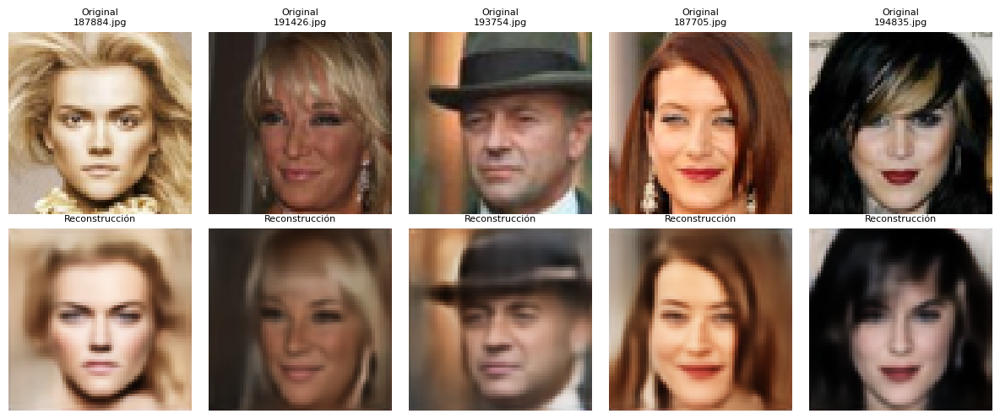

In [12]:
test_indices = sample_rng.choice(len(x_test), size=5, replace=False)
test_reconstructions = autoencoder.predict(x_test[test_indices], verbose=0)
comparison = np.concatenate([x_test[test_indices], test_reconstructions], axis=0)
titles = [f"Original\n{ids_test[i]}" for i in test_indices] + ["Reconstrucción"] * len(test_indices)
show_images(comparison, titles, cols=5, figsize=(12, 5))

Mejor época según val_loss: 30


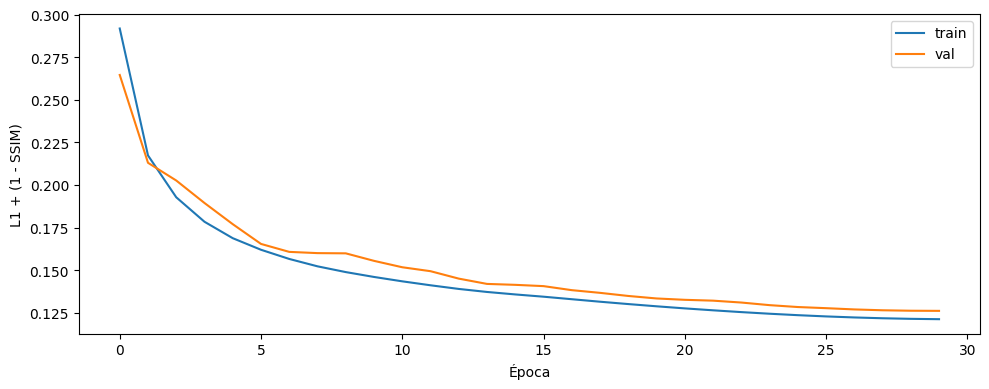

In [13]:
if hasattr(history_ae, "history") and "val_loss" in history_ae.history:
    best_epoch = int(np.argmin(history_ae.history["val_loss"])) + 1
    print(f"Mejor época según val_loss: {best_epoch}")
    plt.figure(figsize=(10, 4))
    plt.plot(history_ae.history["loss"], label="train")
    plt.plot(history_ae.history["val_loss"], label="val")
    plt.xlabel("Época")
    plt.ylabel("L1 + (1 - SSIM)")
    plt.legend()
    plt.tight_layout()
    plt.show()

In [14]:
# FID de reconstrucciones y preparación para el FID del morphing
# El FID compara distribuciones de imágenes; por eso se usa un conjunto de test.
FID_DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
FID_REAL_SAMPLES = min(1000, len(x_test))
FID_BATCH_SIZE = 32


def prepare_images_for_fid(images):
    images = np.asarray(images)
    if images.ndim == 3:
        images = images[..., np.newaxis]
    if images.ndim != 4 or images.shape[-1] not in (1, 3):
        raise ValueError(f"Se esperaban imágenes con forma (N, H, W, 1|3); recibidas {images.shape}")
    if images.dtype != np.uint8:
        images = np.clip(images, 0.0, 1.0)
        images = (images * 255.0).round().astype(np.uint8)
    if images.shape[-1] == 1:
        images = np.repeat(images, 3, axis=-1)
    images = np.transpose(images, (0, 3, 1, 2))
    return torch.from_numpy(np.ascontiguousarray(images))


def calculate_fid(generated_images, real_images, batch_size=FID_BATCH_SIZE):
    generated_images = prepare_images_for_fid(generated_images)
    real_images = prepare_images_for_fid(real_images)
    fid = FrechetInceptionDistance(feature=2048, normalize=False).to(FID_DEVICE)
    with torch.inference_mode():
        for start in range(0, len(real_images), batch_size):
            fid.update(real_images[start:start + batch_size].to(FID_DEVICE), real=True)
        for start in range(0, len(generated_images), batch_size):
            fid.update(generated_images[start:start + batch_size].to(FID_DEVICE), real=False)
    return float(fid.compute().item())

In [15]:
fid_reconstruction_images = x_test[:FID_REAL_SAMPLES]
fid_reconstruction_reference = x_test[FID_REAL_SAMPLES:2 * FID_REAL_SAMPLES]
reconstructed_test_images = autoencoder.predict(
    fid_reconstruction_images,
    batch_size=FID_BATCH_SIZE,
    verbose=0,
)
reconstruction_fid = calculate_fid(
    reconstructed_test_images,
    fid_reconstruction_reference,
)
print(f"FID de reconstrucciones ({FID_REAL_SAMPLES} imágenes): {reconstruction_fid:.4f}")

FID de reconstrucciones (1000 imágenes): 61.1661


---

## **7. FID y morphing mediante interpolación en el espacio latente**

Hemos obtenido un FID de reconstrucción de `61.17`, frente a `63.65` de `AE_complex1_latent` (misma arquitectura, sin pérdida VGG) y `64.40` de `AE_complex2`. Es la primera modificación, tras ampliar el latente, que mejora de forma visible el FID. 

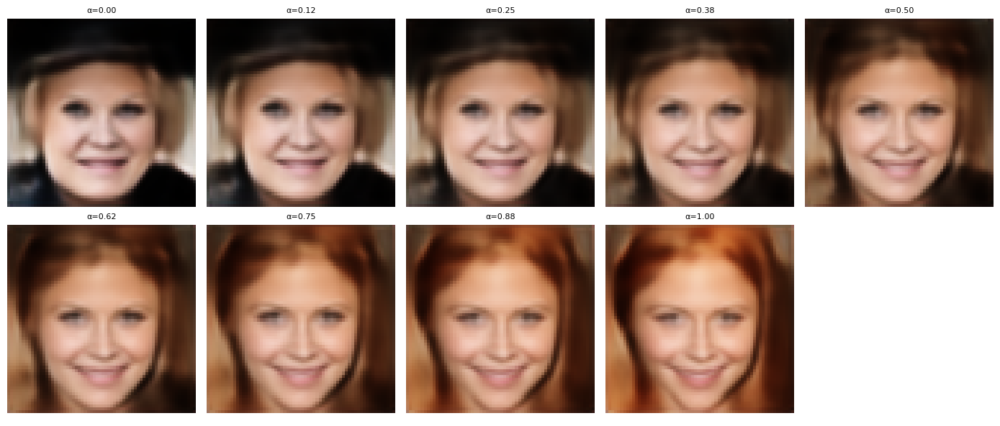

A: 182638.jpg | B: 182640.jpg


In [16]:
def morph_images(image_a, image_b, steps=9):
    if image_a.shape != image_b.shape:
        raise ValueError(f"Las imágenes deben tener la misma forma; recibidas {image_a.shape} y {image_b.shape}")
    z_a = encoder_ae.predict(image_a[None, ...], verbose=0)[0]
    z_b = encoder_ae.predict(image_b[None, ...], verbose=0)[0]
    alphas = np.linspace(0.0, 1.0, steps, dtype=np.float32)
    latent_path = (1.0 - alphas[:, None]) * z_a + alphas[:, None] * z_b
    return alphas, decoder_ae.predict(latent_path, verbose=0)

morph_a_index, morph_b_index = 0, 1
alphas, morph_sequence = morph_images(x_test[morph_a_index], x_test[morph_b_index], steps=9)
show_images(
    morph_sequence,
    [f"α={alpha:.2f}" for alpha in alphas],
    cols=5,
    figsize=(14, 6),
)
print(f"A: {ids_test[morph_a_index]} | B: {ids_test[morph_b_index]}")

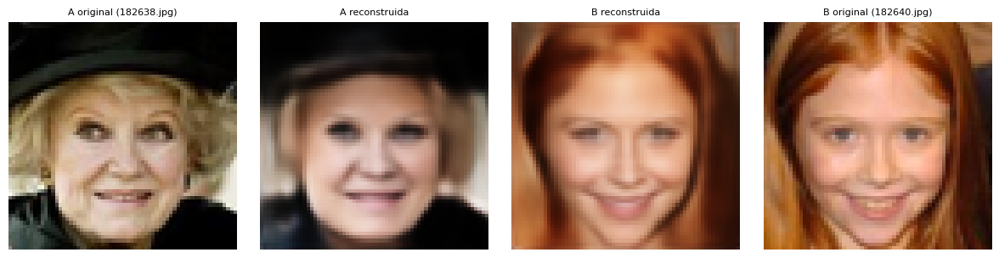

In [17]:
# Comparación de extremos: original frente a reconstrucción usada en la interpolación.
endpoints = np.stack([
    x_test[morph_a_index], morph_sequence[0],
    morph_sequence[-1], x_test[morph_b_index],
])
show_images(
    endpoints,
    [f"A original ({ids_test[morph_a_index]})", "A reconstruida", "B reconstruida", f"B original ({ids_test[morph_b_index]})"],
    cols=4,
    figsize=(12, 3),
)

---

## **8. Secuencia visual y GIF del morphing**


In [18]:
GIF_PATH = PROCESSED_DIR.parent.parent / "gif" / "fusion_ae2_vgg256_morphing.gif"
N_FRAMES = 80
FRAME_MS = 50

z_a = encoder_ae.predict(
    x_test[morph_a_index][None, ...],
    verbose=0,
)[0]
z_b = encoder_ae.predict(
    x_test[morph_b_index][None, ...],
    verbose=0,
)[0]

alphas = np.linspace(0.0, 1.0, N_FRAMES, dtype=np.float32)
z_frames = (1.0 - alphas[:, None]) * z_a + alphas[:, None] * z_b

decoded = decoder_ae.predict(z_frames, verbose=0)

GIF guardado en '/Users/dani22/Desktop/ProyectoCD/morphing/gif/fusion_ae2_vgg256_morphing.gif' | 80 fotogramas


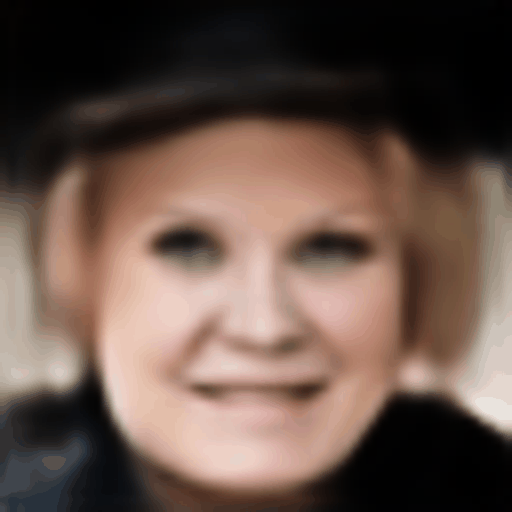

In [19]:
frames = [
    Image.fromarray((np.clip(image, 0, 1) * 255).astype(np.uint8))
    .resize((512, 512), Image.Resampling.BICUBIC)
    for image in decoded
]

gif_path = Path(GIF_PATH).resolve()
gif_path.parent.mkdir(parents=True, exist_ok=True)
if not frames:
    raise RuntimeError("No se generaron fotogramas para el GIF")

frames[0].save(
    gif_path,
    save_all=True,
    append_images=frames[1:],
    duration=FRAME_MS,
    loop=0,
)

print(f"GIF guardado en '{gif_path}' | {len(frames)} fotogramas")
display(IPyImage(filename=str(gif_path)))

---

## **9. Decisiones de diseño, conclusiones y coste**

### **9.1 Resultados**

| Modelo | Latente | Pérdida | FID reconstrucción |
| --- | --- | --- | --- |
| `AE_complex1` | 128 | L1 + SSIM | 72.94 |
| `AE_complex1_latent` | 256 | L1 + SSIM | 63.65 |
| `AE_complex2` (residual) | 256 | L1 + SSIM | 64.40 |
| `AE_complex2_VGG` | 256 | L1 + SSIM + VGG | **61.17** |

La pérdida baja el FID en `2.5` puntos (≈ un `4 %`) respecto a `AE_complex1_latent`, que es su base de comparación directa. La mejora es modesta pero es la única que hemos conseguido tras ampliar el latente. Con 1000 imágenes el FID tiene un ruido bajo, así que la mejora es compatible con un efecto real pequeño, aunque no es una diferencia enorme. Además, el sentido es el esperado: la pérdida se diseñó para recuperar textura y detalle, que es lo que el FID penaliza.

### **9.2 Coste computacional**

- **Parámetros:** el autoencoder tiene exactamente los mismos parámetros que `AE_complex1_latent` (≈ `3.8 M`). La VGG16 truncada tiene unos `0.26 M` de parámetros, pero están congelados y se usan solo durante el entrenamiento.
- **Cómputo por paso de entrenamiento:** en cada paso pasamos la imagen original y la reconstruida por las cuatro primeras convoluciones de VGG16. En total, el paso de entrenamiento cuesta aproximadamente un 50% más que sin VGG. Las activaciones de la imagen original podrían precalcularse una vez para reducir el coste, algo que no hemos hecho por simplicidad.

### **9.3 ¿Merece la pena?**

En este caso creemos que sí, con matices. El coste extra es solo de entrenamiento y es único, mientras que los bloques residuales de `AE_complex2` encarecían además cada imagen generada y no mejoraban nada. Por `2.5` puntos de FID, a cambio de un entrenamiento más caro, es un intercambio razonable, aunque no increíble. Sigue habiendo un límite claro: el FID de `61.17` indica que las reconstrucciones siguen perdiendo detalle, y ni la arquitectura, ni el tamaño del latente, ni la pérdida lo resuelven por completo a esta resolución de `64x64`. Además, la VGG exige entradas RGB; si entrenásemos en escala de grises, habría que replicar el canal antes de calcularla.


---

## **10. Técnicas que probamos y no mantuvimos**

Durante la búsqueda de una arquitectura mejor probamos otras ideas que descartamos para mantener la claridad de la serie, ya que no mejoraban las reconstrucciones de forma apreciable. No incluimos su código ni sus resultados completos, pero las documentamos porque explican decisiones de diseño.

### **10.1 Conexiones de salto (*skip connections*) estilo U-Net**

No las usamos porque **estaríamos haciendo trampa**. Una conexión de salto entre una capa del encoder y la del decoder correspondiente hace llegar información de la imagen directamente al decoder, sin pasar por el vector latente. El modelo reconstruiría mejor, pero la reconstrucción ya no dependería del latente, que es precisamente la representación que queremos interpolar. Además, en el morphing no existe una imagen original de la que tomar los atajos de una mezcla de dos caras. Por eso las conexiones residuales de `AE_complex2` están siempre **dentro** del encoder o del decoder, nunca entre ellos: toda la información tiene que atravesar el latente.

### **10.2 Normalización L2 del latente**

Probamos normalizar el vector a la salida del encoder con una normalización L2, para acotar su rango. El motivo es un problema fundamental de todos estos modelos.

**El problema de los latentes desconocidos.** Durante el entrenamiento, el decoder solo ve los latentes que produce el encoder con las imágenes de `train`. Esos puntos ocupan una región pequeña y desigual del espacio de `256` dimensiones, con enormes zonas **vacías** en las que el decoder nunca ha sido entrenado. En el morphing, el decoder recibe latentes que **nunca ha visto**: mezclas de dos caras, $z_\alpha = (1-\alpha) z_A + \alpha z_B$. Si un $z_\alpha$ cae en una zona vacía o poco representada, el decoder no sabe qué dibujar, y el resultado es una imagen borrosa. **No es un fallo del modelo ni de su capacidad, sino de que nunca ha sido entrenado para ello.**

Lo mismo ocurre, y de forma más grave, si queremos **crear imágenes nuevas**: no basta con elegir un vector aleatorio, hay que **muestrear latentes que sigan la misma distribución** que los que el decoder ha visto. Si no lo hacemos, caemos en las zonas vacías.

Una metáfora: un artista elabora retratos uniendo cubos de Rubik de `3x3`; su método asume esa granularidad. Si le entregamos cubos de `5x5`, los resultados serán mucho peores, y no por falta de destreza, sino porque le damos primitivas distintas a las que conoce. Formalmente, el decoder no tiene una limitación de capacidad, sino un problema de **extrapolación fuera de distribución**: los latentes que le damos no respetan la geometría del espacio sobre el que ha sido entrenado.

**Qué esperábamos de la normalización L2.** Al normalizar, todos los latentes quedan sobre una hiperesfera, de modo que el espacio que el decoder tiene que conocer es más pequeño y compacto, con menos zonas vacías. Pero la interpolación lineal entre dos puntos de una esfera atraviesa su interior (la cuerda), donde la norma es menor que `1` y el decoder tampoco ha visto latentes. Por ello probamos también la **interpolación esférica (slerp)**, que recorre el arco de la esfera. Calculábamos el FID de las imágenes intermedias con slerp y no mejoraba respecto a la interpolación lineal, por lo que mantuvimos esta última. La normalización L2, por su parte, tampoco produjo mejoras significativas a esta escala.

### **10.3 Métodos de muestreo del espacio latente**

Aunque no es el enfoque de este trabajo, la generación de imágenes nuevas es un problema interesante que merece al menos una mención, ya que en la interpolación estamos generando nuevas imágenes. Hemos explicado el problema de la extrapolación fuera de la distribución que puede suceder con la mezcla de nuestras dos caras, y lo mismo ocurre si queremos crear imágenes nuevas: no basta con elegir un vector aleatorio, hay que **muestrear latentes que sigan la misma distribución** que los que el decoder ha visto. 

Estos son algunos de los métodos que funcionan de menor a mayor complejidad, para muestrear latentes completamente nuevos si quisiesemos generar imágenes nuevas y que, a pesar de no haber sido incluídos, hemos probado:

**1. Normal estándar $\mathcal{N}(\mathbf{0}, \mathbf{I})$.** Asume regularización del latente, algo completamente diferente a lo que se observa en los datos reales, por lo que los resultados son muy malos. Mejora si tras el latente se aplica un BatchNormalization, que fuerza la media y varianza de cada dimensión a `0` y `1`.

**2. Uniforme por dimensión.** Calculamos la media $\mu_j$ y la desviación $\sigma_j$ por dimensión. La distribución resultante tiene la misma media y dispersión por canal que los datos, pero con densidad plana, por lo que no se ajusta a la estructura real de los datos.

**3. Gaussiana diagonal $\mathcal{N}(\boldsymbol{\mu}, \text{diag}(\boldsymbol{\sigma}^2))$.** Ajustamos una normal independiente en cada coordenada, $z_j \sim \mathcal{N}(\mu_j, \sigma_j^2)$. *Limitación:* asumimos independencia total entre dimensiones (covarianza diagonal, $\Sigma_{ij} = 0\ \forall\, i \neq j$), una simplificación máxima de la realidad que es falsa.

**4. Gaussiana multivariante $\mathcal{N}(\boldsymbol{\mu}, \boldsymbol{\Sigma})$.** Estimamos el vector de medias $\boldsymbol{\mu} \in \mathbb{R}^D$ y la matriz de covarianza completa $\boldsymbol{\Sigma} \in \mathbb{R}^{D \times D}$, evitando la simplificación anterior. Sin embargo, asumimos unimodalidad (si los datos tienen clases disjuntas, una única gaussiana tenderá a muestrear cerca de la media).

**5. Mezclas gaussianas (GMM).** Extienden la gaussiana multivariante con una suma ponderada de $K$ densidades gaussianas, cada una con su covarianza. Se selecciona un componente $k$ y se extrae el vector de la gaussiana asignada. Se obtienen muy buenos resultados

**6. KNN ($K=10$).** El mecanismo es:

1. Se selecciona un punto $z_i \in \mathcal{Z}_{\text{train}}$ al azar.
2. Se identifican sus $K$ vecinos más cercanos por distancia euclídea, incluyendo el propio punto.
3. Se genera un vector de ponderaciones con una distribución de **Dirichlet**: $K$ pesos positivos que suman `1`.
4. El nuevo vector es la combinación lineal de los vecinos con esos pesos.

Al restringir el muestreo a los vecinos evitamos generar puntos fuera de la distribución latente. *Ponderación:* podríamos promediar directamente los vecinos, pero si son muy distintos el promedio sería un punto intermedio que no se parece a ninguno y la imagen saldría borrosa. Un promedio equivale a una Dirichlet con los mismos pesos para todos; al aleatorizar los pesos ponderamos más a unos vecinos que a otros y podemos generar infinitos puntos distintos dentro del espacio que encierran los `10` vecinos.

**Resultado.** Estos métodos mejoraron de forma marginal con imágenes tan pequeñas. Con imágenes más grandes y realistas y un latente mayor, probablemente funcionarían mejor, y son **imprescindibles para generar caras nuevas**, no solo para el morphing entre dos caras existentes. La interpolación lineal entre dos latentes reales se mantiene como método principal de esta serie.

---

## **11. Mejoras futuras**

Las mejoras que se nos ocurren no pasan por ajustar más esta arquitectura, sino por cambiar de enfoque:

- **Un autoencoder variacional (VAE):** regulariza el espacio latente con una divergencia KL para que se parezca a una gaussiana. Así el decoder se entrena con latentes que ocupan densamente el espacio y el problema de las zonas vacías de la sección 10.2 se aborda directamente durante el entrenamiento, en lugar de corregirse al muestrear. Es la solución natural para generar caras nuevas y producir morphings más suaves.
- **Un autoencoder mayor con latente de `512` dimensiones**, con más capacidad y dos convoluciones por resolución (una `4x4` con `stride=2` que reduce y una `3x3` que mezcla información), como la siguiente arquitectura. Parte de una entrada de un único canal (escala de grises), con las implicaciones discutidas en `AE_complex2`.

```python
# Bloque convolucional común y encoder: por resolución, una conv 4x4 stride 2 (reduce) y una conv 3x3
# (mezcla la información) por cada bloque de filtros.
def conv_block(x, filters, kernel_size=3, strides=1):
    x = layers.Conv2D(filters, kernel_size, strides=strides, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    return layers.LeakyReLU(negative_slope=0.2)(x)


encoder_inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 1), name="encoder_input")
x = encoder_inputs
for filters in (64, 128, 256, 512):
    x = conv_block(x, filters, kernel_size=4, strides=2)
    x = conv_block(x, filters)

x = layers.Flatten()(x)

z = layers.Dense(
    LATENT_DIM,
    kernel_regularizer=keras.regularizers.l2(1e-5),
    name="latent_vector"
)(x)

encoder_ae = keras.Model(encoder_inputs, z, name="encoder_ae")
encoder_ae.summary()

# Decoder: Dense a 4x4x512 y cuatro bloques de upsampling bilineal + dos convoluciones
decoder_inputs = keras.Input(shape=(LATENT_DIM,), name="decoder_input")

x = layers.Dense(4 * 4 * 512, use_bias=False)(decoder_inputs)
x = layers.BatchNormalization()(x)
x = layers.LeakyReLU(negative_slope=0.2)(x)
x = layers.Reshape((4, 4, 512))(x)

# Cada bloque duplica la resolución: 4 -> 8 -> 16 -> 32 -> 64
for filters in (512, 256, 128, 64):
    x = layers.UpSampling2D(size=(2, 2), interpolation="bilinear")(x)
    x = conv_block(x, filters)
    x = conv_block(x, filters)

decoder_outputs = layers.Conv2D(
    1,
    kernel_size=3,
    padding="same",
    activation="sigmoid",
    name="decoder_output"
)(x)

decoder_ae = keras.Model(decoder_inputs, decoder_outputs, name="decoder_ae")
decoder_ae.summary()
```
